# 08 · Landsat 8 — compuestos anuales e índices espectrales

**Qué hace este notebook:** convierte el archivo de imágenes de Landsat 8 (2013–2025) en **una
sola imagen por año** con siete índices espectrales calculados sobre la provincia de Cusco. El
resultado es la serie temporal que el notebook 09 le va a dar de comer a LandTrendr.

**Qué NO hace:** no corre LandTrendr, no valida nada, no clasifica el tipo de cambio. Eso viene
después, y a propósito: si la serie de entrada está mal construida, LandTrendr detectará cambios
que son artefactos del procesamiento y no degradación real. Este notebook existe para que eso no pase.

---

## El problema que estamos resolviendo

Queremos medir **degradación de pastizal altoandino**: el proceso por el cual un pajonal de puna
pierde cobertura vegetal de forma *gradual* y empieza a mostrar suelo desnudo. Eso es distinto de
la deforestación, y la diferencia importa muchísimo para las decisiones técnicas:

| | Deforestación | Degradación de pastizal |
|---|---|---|
| Velocidad | abrupta (un año) | gradual (varios años) |
| Magnitud espectral | grande, inconfundible | pequeña, cerca del ruido |
| Qué queda después | suelo o cultivo, muy distinto del bosque | el mismo pastizal, pero más ralo |
| Confusión principal | casi ninguna | vegetación seca vs. suelo desnudo |

La última fila es la clave. En la puna, durante la época seca, el pajonal (*Festuca*, *Stipa ichu*,
*Calamagrostis*) está **senescente**: amarillo, seco, de pie. Un pastizal sano seco y un pastizal
degradado con suelo expuesto se parecen mucho en el visible. Todo lo que sigue está diseñado
alrededor de ese problema.

---

## Resumen de decisiones

Cada una se explica en detalle en su propia sección. El registro con las citas bibliográficas
completas está en el documento del proyecto `claude/decisiones-metodologicas.md`.

| Decisión | Valor | En una línea |
|---|---|---|
| Satélite | **solo Landsat 8** | Un único sensor mantiene constante la densidad de observaciones en los 13 años. |
| Ventana | **1 jun – 31 ago** | Estación seca plena: pocas nubes y fenología estable. |
| Compuesto | **medoide** | Devuelve una observación real, no un promedio inventado. |
| Índice primario | **−TCW** | Capta la pérdida de humedad del pastizal, donde el NDVI se queda corto. |
| Acompañantes | NDVI, MSAVI, TCG, TCB, BSI, NDMI | Sirven para decir *qué* cambió, no *cuándo*. |
| Escalado | `DN × 0.0000275 − 0.2` | Obligatorio en Collection 2 antes de cualquier índice. |
| Máscara | QA_PIXEL + QA_RADSAT + aerosol | La nube residual se disfraza de degradación. |
| Años sin datos | **no interpolar** | Un dato inventado es peor que un hueco declarado. |

**Orden del proyecto:** 01 límite → 02 fuentes → 03 viabilidad de años → 04 catálogo de indicadores →
05 visor → 06 MapBiomas + Landsat 8 → 07 definir indicadores → **08 compuestos anuales** → 09 LandTrendr.

## 1 · Por qué solo Landsat 8 (y no Landsat 9, 7 o Sentinel-2)

Parece contraintuitivo: si hay más satélites disponibles, ¿por qué no usarlos todos y tener más
imágenes? La respuesta tiene que ver con qué tipo de algoritmo viene después.

**LandTrendr lee la *forma* de la trayectoria temporal de cada píxel.** No le importa el valor
absoluto de un año; le importa cómo cambia de un año al siguiente. Eso lo hace muy sensible a
cualquier cosa que cambie *a mitad de la serie* por razones que no sean el terreno.

### Landsat 9: el problema de la densidad no estacionaria

Landsat 9 se lanzó en septiembre de 2021 y es casi idéntico a Landsat 8 — misma órbita, mismas
bandas, el sensor OLI-2 es un gemelo del OLI. Técnicamente se pueden mezclar sin ninguna
transformación, y al hacerlo el revisit baja de 16 a 8 días. Tentador.

El problema no es la calibración de L9, es **cuándo empieza**. Si lo añadimos, la serie queda así:

```
2013 ──────────────────────── 2021        2022 ──── 2025
  ~5-6 observaciones por ventana seca      ~10-12 observaciones
  (solo L8, cada 16 días)                  (L8+L9, cada 8 días)
```

El compuesto medoide de 2015 se elige entre ~6 candidatos; el de 2024, entre ~12. Con más
candidatos, el medoide tiene más chance de encontrar un píxel realmente limpio y cercano al centro
de la distribución. O sea: **la calidad del compuesto mejora sistemáticamente a partir de 2022**,
no porque el terreno cambie, sino porque hay más datos.

Eso introduce un escalón en la serie exactamente en 2021–2022. Para LandTrendr, un escalón es
precisamente la firma de un disturbio. Terminaríamos con un vértice espurio alrededor de 2022 en
una fracción grande de la provincia, y no habría forma limpia de distinguirlo de un cambio real.

Con solo Landsat 8, los 13 años comparten el mismo régimen de muestreo: mismo sensor, misma órbita,
mismo revisit de 16 días. Las diferencias de densidad entre años quedan reducidas a lo que varían
las nubes, que es ruido aleatorio y no una tendencia.

### Landsat 7: calibración distinta y bandeado

Aportaría observaciones entre 2013 y 2022, pero el sensor ETM+ no mide igual que el OLI: Roy et al.
(2016) documentaron que el NDVI de OLI es sistemáticamente **mayor** que el de ETM+ sobre
superficies vegetadas, y publicaron coeficientes para armonizarlos. Habría que aplicar esa
transformación, que introduce su propia incertidumbre. Y encima arrastra el bandeado SLC-off (desde
2003 le falta ~22 % de cada escena en franjas) y la deriva orbital de sus últimos años, que cambia
la hora de paso y por tanto el ángulo de iluminación.

### Sentinel-2: resolución distinta, sensor distinto

Tiene 10–20 m y pasa cada 5 días, lo cual suena mejor que Landsat en todo. Pero empieza en 2015
(serio para una serie que arranca en 2013), tiene bandas en posiciones espectrales distintas, y
mezclarlo reproduce el mismo problema de densidad no estacionaria que L9, agravado. Queda reservado
para **validación visual**: cuando haya que interpretar un píxel a ojo para ver si el cambio fue
real, su mayor resolución ayuda mucho.

### Lo que perdemos y por qué se puede vivir con eso

Con solo L8 tenemos ~5–6 pasadas por ventana seca, de las cuales las nubes dejan quizá 3–4 útiles.
Es poco, pero alcanza: el compuesto anual solo necesita **un** valor representativo por año, y el
umbral práctico para que el medoide sea robusto es ~3 observaciones. La celda de diagnóstico
verifica exactamente esto año por año; si algún año no llega, la respuesta correcta es ampliar la
ventana unas semanas, no meter otro sensor.

## 2 · Configuración

Todo lo configurable está acá. Para cambiar el experimento no hace falta tocar nada más abajo.

Reutiliza de los notebooks 01, 02 y 06: `buscar_raiz()`, `iniciar_gee()` y el filtro del límite
provincial del INEI.

In [1]:
from datetime import date
from pathlib import Path
import math

import ee
import geemap
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Conexión y colección
# ---------------------------------------------------------------------------
GEE_PROJECT = "viirs-peru"
COLECCION = "LANDSAT/LC08/C02/T1_L2"
# Collection 2 = la recalibración de 2020 de todo el archivo Landsat (mejor geometría y
#   corrección atmosférica que Collection 1, que ya está descontinuada).
# Level 2 = reflectancia de superficie, o sea con la atmósfera ya removida. Imprescindible:
#   comparar años distintos exige que las diferencias sean del terreno, no del aire.
# T1 (Tier 1) = solo escenas con calibración y registro geométrico dentro de tolerancia.
#   Tier 2 existe pero su geolocalización es menos precisa; para una serie temporal
#   píxel a píxel eso es inaceptable.

# Bandas que usamos: nombre común -> banda original de Landsat 8
BANDAS = {"blue": "SR_B2", "green": "SR_B3", "red": "SR_B4",
          "nir": "SR_B5", "swir1": "SR_B6", "swir2": "SR_B7"}
BANDAS_SR = list(BANDAS.keys())

# ---------------------------------------------------------------------------
# Periodo y ventana temporal
# ---------------------------------------------------------------------------
ANIO_INI = 2013      # Landsat 8 se lanzó el 2013-02-11 y entró en operación hacia abril
ANIO_FIN = 2025      # cierre del periodo de análisis del reto
HOY = date.today()
ANIOS = list(range(ANIO_INI, ANIO_FIN + 1))
# La ventana seca de 2026 ya pasó: para clasificarlo como extensión fuera del periodo del
# reto basta subir ANIO_FIN y volver a ejecutar desde la celda de la colección anual.

VENTANA_INI, VENTANA_FIN = "06-01", "09-01"   # 1 jun -> 31 ago (el fin es exclusivo en GEE)
VENTANA_AMPLIA = ("05-15", "09-16")           # respaldo, solo si faltan observaciones claras

# ---------------------------------------------------------------------------
# Umbrales de calidad
# ---------------------------------------------------------------------------
NUBES_MAX = 65          # CLOUD_COVER_LAND máximo por escena (%)
CONF_NUBE_MIN = 2       # Cloud Confidence de QA_PIXEL: 2 = media, 3 = alta. Enmascara >= este valor
ENMASCARAR_NIEVE = True # en puna la nieve y la helada brillante contaminan TCB y TCW
ENMASCARAR_AEROSOL = True
OBS_MIN_ANIO = 3        # observaciones claras por píxel/año para que el medoide sea robusto
OBS_MIN_SERIE = 6       # años válidos por píxel que exige LandTrendr (minObservationsNeeded)

# ---------------------------------------------------------------------------
# Coeficientes Tasseled Cap
# ---------------------------------------------------------------------------
# Baig et al. (2014), Remote Sensing Letters 5(5):423-431 — derivados para Landsat 8 OLI.
# Crist (1985) es la alternativa, derivada para TM y la que usa LT-GEE internamente.
TC_COEF = {
    "Baig2014": {
        "TCB": [0.3029, 0.2786, 0.4733, 0.5599, 0.5080, 0.1872],
        "TCG": [-0.2941, -0.2430, -0.5424, 0.7276, 0.0713, -0.1608],
        "TCW": [0.1511, 0.1973, 0.3283, 0.3407, -0.7117, -0.4559],
    },
    "Crist1985": {
        "TCB": [0.2043, 0.4158, 0.5524, 0.5741, 0.3124, 0.2303],
        "TCG": [-0.1603, -0.2819, -0.4934, 0.7940, -0.0002, -0.1446],
        "TCW": [0.0315, 0.2021, 0.3102, 0.1594, -0.6806, -0.6109],
    },
}
TC_FUENTE = "Baig2014"
TC_ORDEN = ["blue", "green", "red", "nir", "swir1", "swir2"]

# ---------------------------------------------------------------------------
# Índices
# ---------------------------------------------------------------------------
INDICE_PRIMARIO = "negTCW"                                      # segmentación de LandTrendr
INDICES_FTV = ["NDVI", "MSAVI", "TCG", "TCB", "BSI", "NDMI"]     # bandas acompañantes
INDICES = [INDICE_PRIMARIO] + INDICES_FTV

# ---------------------------------------------------------------------------
# Salida
# ---------------------------------------------------------------------------
GRID_CRS = "EPSG:32719"   # UTM 19S. La celda del límite verifica si la provincia cruza a 18S
ESCALA = 30               # resolución nativa de Landsat, sin remuestreo


def buscar_raiz(inicio=None):
    """Sube por las carpetas hasta encontrar la raíz del proyecto (la que tiene el límite provincial)."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg").is_file():
            return carpeta
    raise FileNotFoundError("No encuentro data/raw/Provincia/PROVINCIA.gpkg desde esta ubicación.")


def iniciar_gee(proyecto=GEE_PROJECT):
    try:
        ee.Initialize(project=proyecto)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=proyecto)


iniciar_gee()
RAIZ = buscar_raiz()
SALIDA = RAIZ / "outputs" / "04_serie_anual_landsat"

print("Raíz del proyecto :", RAIZ)
print("Colección         :", COLECCION, "(solo Landsat 8)")
print("Periodo           :", ANIOS[0], "-", ANIOS[-1], f"({len(ANIOS)} años)   | hoy: {HOY}")
print("Ventana seca      :", VENTANA_INI, "->", VENTANA_FIN, "(fin exclusivo)")
print("Índice primario   :", INDICE_PRIMARIO)
print("Acompañantes      :", ", ".join(INDICES_FTV))
print("Tasseled Cap      :", TC_FUENTE)
CONFIG_LISTA = True

Raíz del proyecto : F:\Cobertura de suelo
Colección         : LANDSAT/LC08/C02/T1_L2 (solo Landsat 8)
Periodo           : 2013 - 2025 (13 años)   | hoy: 2026-10-23
Ventana seca      : 06-01 -> 09-01 (fin exclusivo)
Índice primario   : negTCW
Acompañantes      : NDVI, MSAVI, TCG, TCB, BSI, NDMI
Tasseled Cap      : Baig2014


## 3 · Provincia de Cusco (límite INEI)

Mismo polígono y mismo filtro que el notebook 01: `data/raw/Provincia/PROVINCIA.gpkg`,
departamento `08`, provincia `01`.

La geometría se simplifica a ~0.0001° (unos 11 m en el ecuador, menos de medio píxel de Landsat).
Esto no es por precisión sino por costo: cada consulta a Earth Engine lleva la geometría consigo,
y un polígono con miles de vértices hace lentas todas las operaciones sin aportar nada a 30 m de
resolución.

La celda también comprueba algo fácil de pasar por alto: **Cusco está justo sobre el meridiano
−72°**, que es la frontera entre las zonas UTM 18S y 19S. Si la provincia cruza esa línea, hay que
elegir una sola zona para todo el análisis y saber que la parte del otro lado queda ligeramente
deformada. La alternativa — procesar cada mitad en su zona — obligaría a remuestrear en la frontera,
que es peor.

In [2]:
GPKG = RAIZ / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg"
gdf = gpd.read_file(GPKG)
prov = gdf[(gdf["ccdd"] == "08") & (gdf["ccpp"] == "01")]
assert len(prov) == 1, "El filtro de provincia no devolvió exactamente 1 registro"

aoi = ee.Geometry(prov.geometry.iloc[0].simplify(0.0001, preserve_topology=True).__geo_interface__)

lon_min, lat_min, lon_max, lat_max = prov.total_bounds
area_km2 = prov.to_crs(epsg=32719).area.iloc[0] / 1e6

print("Provincia :", prov["nombprov"].iloc[0], "| departamento:", prov["nombdep"].iloc[0])
print("CRS       :", gdf.crs, "| fuente declarada:", prov["fuente"].iloc[0])
print(f"Área      : {area_km2:,.1f} km²")
print("Límites   :", [round(v, 4) for v in prov.total_bounds], "(lon/lat)")

zona_min = int((lon_min + 180) // 6) + 1
zona_max = int((lon_max + 180) // 6) + 1
if zona_min == zona_max:
    print(f"\n→ La provincia cae entera en UTM {zona_min}S. GRID_CRS = {GRID_CRS} es correcto.")
else:
    print(f"\n⚠ La provincia cruza de UTM {zona_min}S a {zona_max}S (meridiano -72°).")
    print(f"  Se usa {GRID_CRS} para todo: la parte en la zona {zona_min}S queda algo deformada,")
    print(f"  pero una sola grilla evita remuestrear en la frontera entre zonas.")

# Cuántos píxeles de Landsat cubren la provincia (para dimensionar las descargas más adelante)
print(f"\nPíxeles de {ESCALA} m que cubren el área: ~{area_km2 * 1e6 / ESCALA**2:,.0f}")

Provincia : CUSCO | departamento: CUSCO
CRS       : EPSG:4326 | fuente declarada: V Censo Nacional Economico
Área      : 530.1 km²
Límites   : [np.float64(-72.168), np.float64(-13.6492), np.float64(-71.8046), np.float64(-13.4295)] (lon/lat)

⚠ La provincia cruza de UTM 18S a 19S (meridiano -72°).
  Se usa EPSG:32719 para todo: la parte en la zona 18S queda algo deformada,
  pero una sola grilla evita remuestrear en la frontera entre zonas.

Píxeles de 30 m que cubren el área: ~589,055


## 4 · Qué nos dan las bandas de Landsat 8, y por qué usamos estas seis

Landsat 8 lleva dos instrumentos: **OLI** (Operational Land Imager), que mide 9 bandas en el
visible, infrarrojo cercano e infrarrojo de onda corta, y **TIRS** (Thermal Infrared Sensor), con 2
bandas térmicas. De las 11 bandas totales usamos 6. Esta sección explica qué mide cada una y por
qué entró o quedó fuera.

### Las seis que usamos

| Banda | Nombre | λ (µm) | Qué mide físicamente | Por qué importa para pastizal |
|---|---|---|---|---|
| `SR_B2` | Azul | 0.45–0.51 | Muy dispersada por la atmósfera; refleja suelos claros | Entra en BSI y en el brillo (TCB). Ayuda a detectar suelo expuesto |
| `SR_B3` | Verde | 0.53–0.59 | Pico de reflectancia de la clorofila | Es el "verde" que vemos. Baja cuando la planta se estresa |
| `SR_B4` | Rojo | 0.64–0.67 | **Absorción** de clorofila: vegetación sana refleja poco | Sube cuando hay menos vegetación o la que hay está seca |
| `SR_B5` | NIR | 0.85–0.88 | Dispersión en la estructura interna de la hoja | El salto rojo→NIR es la firma de vegetación viva. Cae con la biomasa |
| `SR_B6` | SWIR1 | 1.57–1.65 | **Absorción por agua** en hoja y suelo | El más informativo acá: el pastizal degradado retiene menos agua |
| `SR_B7` | SWIR2 | 2.11–2.29 | Agua + materia seca (lignina, celulosa) | Ayuda a separar vegetación seca de suelo desnudo |

El par **rojo / NIR** es la base de toda la teledetección de vegetación: una hoja viva absorbe rojo
(la clorofila lo usa para fotosintetizar) y dispersa NIR (la estructura celular lo rebota). Ese
contraste brutal entre dos longitudes de onda vecinas es lo que mide el NDVI.

Pero acá está el problema central de nuestro caso: **ese contraste depende de que la hoja esté
viva**. En la época seca el pajonal está senescente — en pie, pero seco. Sin clorofila activa, el
contraste rojo/NIR se desploma y el NDVI de un pastizal sano-pero-seco se parece al de un pastizal
degradado. Por eso las bandas **SWIR** son las protagonistas de este análisis y no un accesorio: el
agua absorbe fuertemente en 1.6 y 2.2 µm, así que el SWIR mide *contenido de humedad* en vez de
*actividad fotosintética*. Un pastizal degradado, con menos biomasa y menos capacidad de retener
agua, refleja más SWIR — y eso ocurre esté verde o seco.

### Las cinco que no usamos, y por qué

- **`SR_B1` (costera/aerosol, 0.43–0.45 µm)** — diseñada para estudios de agua y para estimar
  aerosoles. No aporta a vegetación y es la banda más afectada por la atmósfera. Sí la usa
  indirectamente el producto `SR_QA_AEROSOL`, que sí consultamos para la máscara.
- **`B8` (pancromática, 15 m)** — la única a 15 m, pero es una sola banda ancha en blanco y negro.
  Sirve para afinar visualmente una composición, no para calcular índices, que necesitan bandas
  espectralmente separadas. Además no existe como producto de reflectancia de superficie.
- **`B9` (cirrus, 1.36–1.38 µm)** — mide nubes altas de hielo. No se usa para el terreno, pero
  alimenta el bit de cirrus de `QA_PIXEL`, que sí aplicamos en la máscara.
- **`B10`, `B11` (térmicas, 100 m remuestreadas a 30 m)** — miden temperatura de superficie, que
  sí se relaciona con estrés hídrico: una superficie con poca vegetación y poca humedad se calienta
  más. Las dejamos fuera por tres razones: su resolución real es 100 m (el dato a 30 m es
  interpolado), B11 tiene un problema conocido de luz difusa que llevó al USGS a recomendar no
  usarla sola, y en terreno de montaña la temperatura queda dominada por la topografía —
  orientación de la ladera, hora de paso, sombra — más que por el estado del pastizal. Es un
  candidato razonable para una capa de atribución más adelante, no para la serie principal.

### Bandas de calidad (no son medidas, son metadatos por píxel)

- **`QA_PIXEL`** — resultado del algoritmo CFMask: qué es cada píxel (nube, sombra, nieve, agua,
  relleno) y con qué confianza.
- **`QA_RADSAT`** — qué bandas se saturaron en ese píxel.
- **`SR_QA_AEROSOL`** — cuánto aerosol había, o sea cuánta confianza merece la corrección
  atmosférica en ese píxel.

Las tres se usan en la máscara de la sección 6.

## 5 · Los siete índices: qué mide cada uno y qué papel cumple

Un índice espectral es una combinación aritmética de bandas que concentra una propiedad del
terreno en un solo número. La razón de usar varios no es redundancia: **cada uno falla de una
manera distinta**, y esas fallas no se superponen.

Importante: solo **uno** entra a LandTrendr como índice de segmentación. Los otros seis van como
"bandas acompañantes" (`ftvList`), que se ajustan en los mismos puntos de quiebre que detecte el
primario. Es decir: uno decide *cuándo* pasó algo, los otros seis describen *qué* pasó.

### El primario: −TCW

**Tasseled Cap** es una transformación lineal de las seis bandas, diseñada en los años 70 para
cultivos, que las rota a tres ejes con significado físico:

- **TCB (Brightness)** — el brillo general. Sube con suelo desnudo, roca y nieve.
- **TCG (Greenness)** — vegetación fotosintéticamente activa. Es pariente conceptual del NDVI.
- **TCW (Wetness)** — **contenido de humedad** en vegetación y suelo. Son los pesos positivos del
  visible contra los pesos fuertemente negativos del SWIR (−0.71 y −0.46): básicamente mide
  *cuánta agua absorbe esta superficie*.

Usamos **TCW invertido** (`negTCW = −TCW`) como índice primario. Dos razones:

**Por qué TCW y no NDVI.** Ya está dicho arriba: en pajonal senescente de época seca el NDVI tiene
poco rango dinámico y no distingue vegetación seca de suelo desnudo. TCW no depende de la clorofila,
sino del agua, y un pastizal degradado retiene menos agua independientemente de su estado
fenológico. La evidencia empírica apunta en la misma dirección: Dara et al. (2020, RSE 239:111667)
compararon métricas espectrotemporales en estepa post-soviética con gradiente de pastoreo y la
mediana de TCW superó a todas las demás métricas individuales (78 % de exactitud global); Gelabert
et al. (2021, RSE 262:112521) obtuvieron su mejor resultado en pérdida de pastizal usando series de
TCB y TCW ajustadas por LandTrendr (F1 = 0.85); y Sonnenschein et al. (2011, RSE 115:1408–1420)
hallaron que, tomando las fracciones de unmixing espectral como referencia física, la similitud
decrece de TCG a SAVI y por último NDVI.

**Por qué invertido.** LT-GEE exige que la **pérdida de vegetación sea un delta positivo**: el
algoritmo busca segmentos donde el índice sube. Como la degradación hace *bajar* la humedad, TCW
baja — así que lo multiplicamos por −1 para que la degradación suba. Olvidar este paso hace que
LandTrendr clasifique las degradaciones como recuperaciones y viceversa. Es el error más común al
usar la herramienta.

### Los seis acompañantes

| Índice | Fórmula | Qué capta | Su debilidad |
|---|---|---|---|
| **NDVI** | `(nir − red)/(nir + red)` | Verdor, vigor fotosintético | Se satura con vegetación densa; no separa vegetación seca de suelo. Va igual porque es el estándar universal y hace comparable este trabajo con cualquier otro |
| **MSAVI** | `(2·nir + 1 − √((2·nir+1)² − 8·(nir−red)))/2` | Verdor **corregido por suelo** | Más complejo de interpretar. Es el NDVI arreglado justo para el caso en que el suelo asoma entre las matas — o sea, para degradación |
| **TCG** | combinación lineal | Vegetación activa, en el espacio Tasseled Cap | Comparte la limitación de la clorofila con NDVI, pero es consistente con TCW y TCB |
| **TCB** | combinación lineal | Brillo: suelo desnudo, roca | Sube también con nieve y con suelos claros naturales |
| **BSI** | `((swir1+red) − (nir+blue))/((swir1+red) + (nir+blue))` | **Suelo desnudo**, directamente | Confunde suelo con vegetación muy seca. Es el indicador más directo de degradación, y su subida es la confirmación que buscamos |
| **NDMI** | `(nir − swir1)/(nir + swir1)` | Humedad del dosel | Correlacionado con TCW (comparte el SWIR1), pero más simple e interpretable. Suele caer *antes* que el NDVI cuando empieza el estrés |

### Cómo se usan juntos

La idea es **evidencia cruzada**. En el año que LandTrendr marca como quiebre, mirás la dirección
de todos:

```
negTCW ↑  (menos humedad)
NDVI   ↓  (menos verdor)
MSAVI  ↓  (menos verdor, ajustado por suelo)
BSI    ↑  (más suelo desnudo)
TCB    ↑  (más brillo)
NDMI   ↓  (menos humedad en el dosel)
```

Si **todos** se mueven en la dirección esperada, es degradación con alta confianza. Si solo uno se
mueve, es casi seguro ruido, nube mal enmascarada, o un cambio de otro tipo. Una regla práctica:
exigir que al menos 4 de 6 vayan en la dirección esperada.

Y esto también permite **separar tipos de cambio**: una quema da pérdida de un año con recuperación
rápida; una conversión a cultivo da patrón geométrico y alta variabilidad entre años; la degradación
por sobrepastoreo da pérdida larga y sostenida con BSI en subida. Eso se formaliza en el notebook de
atribución, no acá.

## 6 · Las funciones: escalado, máscara de calidad, índices y medoide

### 6.1 Escalado — el paso que no se puede olvidar

Las bandas de Collection 2 Level 2 **no vienen en reflectancia**: vienen como enteros de 16 bits
para ahorrar espacio. La conversión oficial del USGS es:

```
reflectancia = DN × 0.0000275 − 0.2
```

Esto es obligatorio y es una fuente de error silencioso clásica. Por qué importa tanto acá:

- **Tasseled Cap, MSAVI y BSI tienen términos aditivos.** Una combinación lineal con constantes
  (`2·nir + 1`, o los pesos de TC) solo tiene sentido si las entradas están en el rango físico
  0–1. Con enteros de 16 bits, el resultado es basura numérica.
- **Incluso el NDVI lo necesita.** Es un cociente, así que el factor multiplicativo 0.0000275 se
  cancela... pero el **offset −0.2 no**. `(a−b)/(a+b)` no es invariante a sumar una constante.
  Saltarse el escalado da un NDVI que *parece* razonable (sale entre −1 y 1) pero está sesgado.
  Es el peor tipo de bug: no falla, solo miente.

Después de escalar, recortamos al rango físico `[0, 1]`. El valor de relleno de Collection 2 es
`0`, que al escalar da −0.2: cae fuera de rango y queda enmascarado automáticamente, que es
justo lo que queremos.

### 6.2 Máscara de calidad — por qué somos estrictos

Un píxel contaminado por nube delgada tiene SWIR más bajo y NIR más alto de lo real. Traducido a
nuestros índices: **la nube residual se ve igual que degradación**. Y lo peor es que no es ruido
aleatorio: si un año tuvo más bruma que otro, el sesgo es sistemático y LandTrendr lo lee como
tendencia.

Por eso enmascaramos en tres niveles:

**`QA_PIXEL`** (del algoritmo CFMask) — bits individuales:

| Bit | Qué marca | Por qué lo quitamos |
|---|---|---|
| 0 | Relleno | Fuera de la huella de la escena |
| 1 | Nube dilatada | Borde de nube: el USGS ya expande las nubes de alta confianza porque sus bordes contaminan |
| 2 | Cirrus | Nube alta de hielo, difícil de ver pero sí altera la reflectancia |
| 3 | Nube | Nube densa |
| 4 | Sombra de nube | Tan problemática como la nube: baja toda la reflectancia |
| 5 | Nieve | En puna hay nieve y helada estacional, que dispara TCB y distorsiona TCW |

Más la **confianza de nube** (bits 8–9), donde enmascaramos desde **media**, no solo alta. Esta es
una decisión conservadora y vale explicarla: el default del USGS y de LT-GEE es quitar solo alta
confianza. Pero en montaña la nube delgada es frecuente y el sesgo que produce apunta siempre en la
misma dirección (falsa degradación), así que preferimos perder píxeles a ganar señal falsa. El
contrapeso: en puna los suelos claros y la nieve hacen que CFMask marque de más, así que la celda
de visualización incluye una comprobación a ojo. Si se ve que estamos perdiendo demasiado terreno
real, `CONF_NUBE_MIN = 3` lo relaja.

**`QA_RADSAT`** — píxeles donde alguna banda saturó el detector. En superficies muy brillantes
(nieve, arena clara) el sensor llega a su techo y el valor deja de ser proporcional a la radiancia
real. Un valor saturado no es un valor medido.

**`SR_QA_AEROSOL`** — cuando el aerosol atmosférico era alto, la corrección atmosférica es menos
confiable. El propio catálogo de GEE advierte sobre esto, en particular con ángulos cenitales
solares grandes, que es exactamente nuestro caso: invierno austral en latitud 13°S.

### 6.3 El medoide — por qué no un promedio

Para resumir varias observaciones del año en una, lo intuitivo es promediar, o tomar la mediana
banda por banda. Y es lo que hacía el notebook 06. Pero hay un problema.

Imaginá un píxel con tres observaciones limpias en la ventana seca:

| | blue | green | red | nir | swir1 | swir2 |
|---|---|---|---|---|---|---|
| 15 jun | 0.08 | 0.11 | 0.14 | 0.26 | 0.30 | 0.22 |
| 17 jul | 0.09 | 0.12 | 0.16 | 0.24 | 0.33 | 0.25 |
| 18 ago | 0.11 | 0.14 | 0.19 | 0.22 | 0.36 | 0.28 |
| **mediana por banda** | 0.09 | 0.12 | 0.16 | 0.24 | 0.33 | 0.25 |

La mediana por banda toma, para cada banda independientemente, el valor del medio. Acá coincide con
julio, pero eso es casualidad: con más observaciones, la mediana del azul puede venir de junio, la
del NIR de agosto y la del SWIR1 de julio. **El píxel resultante es una quimera que nunca se
observó.**

¿Por qué es un problema concreto y no un escrúpulo? Porque **Tasseled Cap es una combinación lineal
de las seis bandas simultáneas**. Sus coeficientes fueron derivados asumiendo que las seis vienen
de la misma medición, de la misma superficie, en el mismo instante. Si mezclás bandas de fechas
distintas, rompés las relaciones entre ellas y TCW deja de medir humedad: mide una mezcla sin
interpretación física. Lo mismo vale para cualquier análisis de fracciones (unmixing) más adelante.

El **medoide** resuelve esto: calcula, para cada píxel, la distancia euclidiana de cada observación
al vector mediano, y se queda con la **observación completa** de distancia mínima. El resultado es
siempre un píxel real, medido un día real, con sus seis bandas coherentes entre sí. En el ejemplo
elegiría la fila de julio entera.

La guía de LT-GEE declara explícitamente preferir el medoide, y Flood (2013, Remote Sensing
5(12):6481) mostró que representa la serie mejor que el compuesto de máximo NDVI, con residuos hasta
un orden de magnitud menores. *No hay consenso absoluto* — un estudio de 2023 en el IJDE encontró
mejor clasificación con la mediana, y señala que el medoide puede dar discontinuidad espacial (los
píxeles vecinos pueden venir de días distintos). Pero para alimentar un segmentador que lee
trayectorias, la coherencia radiométrica pesa más.

La implementación es la canónica de LT-GEE: se apila `[distancia, banda1..banda6]` y se reduce con
`min(7)`, que devuelve las siete salidas del píxel donde la primera es mínima. Un truco elegante:
el reductor `min(k)` de Earth Engine ordena por el primer input y arrastra los demás.

In [3]:
def escalar(img):
    """Convierte los enteros de Collection 2 a reflectancia y recorta al rango físico [0, 1].

    SR = DN * 0.0000275 - 0.2  (factores oficiales de USGS, LSDS-1619).
    El valor de relleno es 0, que al escalar da -0.2: cae fuera de rango y queda enmascarado.
    """
    sr = (img.select(list(BANDAS.values()), BANDAS_SR)
             .multiply(0.0000275).add(-0.2))
    en_rango = sr.gte(0).And(sr.lte(1)).reduce(ee.Reducer.min())
    # copyProperties() devuelve un ee.Element, no un ee.Image: hay que volver a castear
    # o el siguiente .updateMask() falla con AttributeError.
    return ee.Image(sr.updateMask(en_rango).copyProperties(img, ["system:time_start"]))


def mascara_calidad(img):
    """Máscara de píxel limpio a partir de las tres bandas de calidad de Collection 2."""
    qa = img.select("QA_PIXEL")

    # Bits 0-5: relleno, nube dilatada, cirrus, nube, sombra de nube, nieve.
    # bitwiseAnd con 63 (= 0b111111) mira los seis de golpe; con 31 (= 0b11111) deja pasar la nieve.
    bits = 63 if ENMASCARAR_NIEVE else 31
    limpio = qa.bitwiseAnd(bits).eq(0)

    # Confianza de nube (bits 8-9): 0 ninguna, 1 baja, 2 media, 3 alta.
    limpio = limpio.And(qa.rightShift(8).bitwiseAnd(3).lt(CONF_NUBE_MIN))
    # Confianza alta de sombra de nube (bits 10-11) y de cirrus (bits 14-15).
    limpio = limpio.And(qa.rightShift(10).bitwiseAnd(3).neq(3))
    limpio = limpio.And(qa.rightShift(14).bitwiseAnd(3).neq(3))

    # Saturación radiométrica en cualquier banda: un valor saturado no es un valor medido.
    limpio = limpio.And(img.select("QA_RADSAT").eq(0))

    # Aerosol alto (bits 6-7 = 3): la corrección atmosférica es poco confiable ahí.
    if ENMASCARAR_AEROSOL:
        limpio = limpio.And(img.select("SR_QA_AEROSOL").rightShift(6).bitwiseAnd(3).neq(3))

    return limpio.rename("limpio")


def preparar(img):
    """Escena lista para componer: reflectancia escalada y enmascarada por calidad."""
    return ee.Image(escalar(img).updateMask(mascara_calidad(img)))


def tasseled_cap(sr):
    """Añade TCB, TCG, TCW y negTCW. Cada componente es una combinación lineal de las 6 bandas."""
    coef = TC_COEF[TC_FUENTE]
    bandas = sr.select(TC_ORDEN)
    salida = []
    for nombre in ["TCB", "TCG", "TCW"]:
        comp = (bandas.multiply(ee.Image.constant(coef[nombre]))
                      .reduce(ee.Reducer.sum()).rename(nombre))
        salida.append(comp)
    # negTCW: invertido para que la PÉRDIDA de vegetación sea un delta POSITIVO, como exige LT-GEE
    salida.append(salida[2].multiply(-1).rename("negTCW"))
    return sr.addBands(salida)


def agregar_indices(sr):
    """Añade los 7 índices a una imagen con bandas blue, green, red, nir, swir1, swir2."""
    ndvi = sr.normalizedDifference(["nir", "red"]).rename("NDVI")
    ndmi = sr.normalizedDifference(["nir", "swir1"]).rename("NDMI")

    nir, red = sr.select("nir"), sr.select("red")
    msavi = (nir.multiply(2).add(1)
               .subtract(nir.multiply(2).add(1).pow(2)
                            .subtract(nir.subtract(red).multiply(8)).sqrt())
               .divide(2).rename("MSAVI"))

    bsi = sr.expression(
        "((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue))",
        {"swir1": sr.select("swir1"), "red": red, "nir": nir, "blue": sr.select("blue")}
    ).rename("BSI")

    return tasseled_cap(sr).addBands([ndvi, ndmi, msavi, bsi])


def medoide(col, bandas=None):
    """Compuesto por medoide: la OBSERVACIÓN REAL más cercana a la mediana multibanda.

    A diferencia de la mediana por banda, devuelve un píxel que existió: sus 6 bandas vienen
    todas del mismo día, así que las relaciones entre bandas (de las que dependen las
    componentes Tasseled Cap) quedan intactas.

    Implementación canónica de LT-GEE: se apila [distancia, *bandas] y se reduce con min(n+1),
    que ordena por el primer input (la distancia) y arrastra las bandas del píxel ganador.
    """
    bandas = bandas or BANDAS_SR
    col = col.select(bandas)
    mediana = col.median()

    def con_distancia(img):
        dist = (img.subtract(mediana).pow(2)
                   .reduce(ee.Reducer.sum()).sqrt().rename("dist"))
        return dist.addBands(img)

    n = len(bandas)
    reducido = col.map(con_distancia).reduce(ee.Reducer.min(n + 1))
    # min(k) nombra las salidas min, min1, min2...: la 0 es la distancia, las demás las bandas
    return reducido.select(list(range(1, n + 1)), bandas)


print("Funciones listas:", ", ".join(["escalar", "mascara_calidad", "preparar",
                                      "tasseled_cap", "agregar_indices", "medoide"]))

Funciones listas: escalar, mascara_calidad, preparar, tasseled_cap, agregar_indices, medoide


## 7 · Por qué la ventana es junio–agosto

Hay que elegir qué parte del año representa a cada año. Tres opciones, y la decisión no es obvia.

### Todo el año: no

En Cusco la estación de lluvias va aproximadamente de noviembre a marzo. Incluirla trae dos
problemas:

1. **Nubes.** Muchas más escenas inutilizables, y lo que sobrevive está sesgado hacia los días
   raros de cielo despejado en temporada húmeda.
2. **Fenología.** El pastizal es verde en lluvias y seco en secas. Es una oscilación enorme —
   mucho mayor que la señal de degradación que buscamos — y es *normal*, no es degradación.
   Mezclarla con la señal de interés es como intentar medir la deriva de un sensor sin filtrar
   primero la portadora.

### Marzo–septiembre: tampoco

Esta era la idea original y vale explicar por qué se descartó, porque el motivo es sutil e
interesante.

Marzo y abril son el final de la temporada de lluvias: el pastizal todavía está verde. Si la
ventana los incluye, el compuesto de cada año se arma con una mezcla de "fin de lluvias" y
"estación seca". El problema es que **la proporción de la mezcla cambia entre años**, porque
depende de qué escenas sobrevivieron a las nubes ese año en particular. Un año con marzo despejado
queda más verde; un año con marzo nublado queda más seco.

O sea: la **fecha efectiva** del compuesto se desplaza de año en año de forma impredecible. Para
LandTrendr, que lee la trayectoria, eso es ruido estructurado que se parece a cambio real. Es el
equivalente a muestrear una señal periódica con un reloj que deriva: la variación que ves no está
en la señal, está en tu muestreo.

### Junio–agosto: sí

Estación seca plena. El pastizal está en su estado más estable y repetible, hay pocas nubes, y la
fecha efectiva del compuesto es consistente entre años. El costo: solo ~5–6 pasadas de Landsat 8
en esos tres meses, de las que las nubes dejan quizá 3–4.

La guía de LT-GEE recomienda explícitamente probar varias ventanas y advierte que los usuarios del
hemisferio sur deben adaptarlas; Pasquarella et al. (2022, IJAEOG) muestran que las fechas de
inicio y fin afectan tanto el ajuste como los vértices detectados. Como precedente regional,
Cano et al. (2023, Sustainability 15(21):15472) usaron abril–octubre en la puna de Junín, aunque
sin analizar el efecto fenológico de esa amplitud.

### El respaldo: 15 may – 15 sep

Si algún año no llega a 3 observaciones claras con jun–ago, la respuesta correcta es **ampliar unas
semanas hacia los bordes de la estación seca**, no meter otro satélite. Mayo y septiembre siguen
siendo secos; marzo y abril no. La celda 8.1 compara las dos ventanas para decidir con datos y no
a priori.

## 8 · La colección anual 2013–2025

Por cada año: filtrar la ventana seca → descartar escenas demasiado nubladas → escalar y enmascarar
píxel a píxel → medoide → calcular los 7 índices → contar observaciones claras.

**Sobre el filtro de escena (`CLOUD_COVER_LAND < 65 %`).** Es un filtro grueso, a nivel de escena
completa, que solo sirve para no arrastrar escenas casi inútiles. El trabajo fino lo hace la máscara
por píxel. El umbral es deliberadamente permisivo: una escena con 60 % de nubes puede tener la
provincia entera despejada, y en montaña descartarla por su promedio global es tirar datos buenos.
Usamos `CLOUD_COVER_LAND` y no `CLOUD_COVER` porque el porcentaje sobre tierra es el relevante acá
— el agua y la nieve inflan el valor global sin decir nada sobre la calidad del píxel de pastizal.

*Nota de consistencia:* el notebook 06 usaba `CLOUD_COVER < 30`, bastante más estricto. El cambio es
deliberado: ese umbral descartaba escenas con provincia despejada, y acá el enmascarado por píxel es
más agresivo que el de 06 (bits 0–5 + confianza media vs. solo bits 0–4), así que el filtro grueso
puede aflojarse.

**Sobre el mosaico entre path/row.** La provincia probablemente cae en más de una escena de Landsat.
El orden importa: **primero enmascarar cada escena, después componer**. Así las franjas donde dos
path/row se solapan aportan observaciones extra en vez de estorbar — un píxel en la franja de
solape puede tener el doble de oportunidades de salir limpio. Hacerlo al revés (mosaico primero)
obligaría a elegir una escena por región y desperdiciaría esas observaciones.

**Sobre la banda `n_obs`.** Cuenta, píxel a píxel, cuántas observaciones limpias entraron en el
compuesto de ese año. Es el control de calidad de toda la serie y hay que llevarlo hasta el final:
un píxel que en 2017 tuvo una sola observación limpia tiene un valor mucho menos confiable que uno
con cinco, y eso debe pesar al interpretar los resultados de LandTrendr. Umbrales: `>= 3` año bueno,
`1–2` baja calidad, `0` año enmascarado.

**Sobre los años sin datos: no interpolar.** Si un año queda sin observaciones válidas, se deja
enmascarado. La API de LT-GEE indica que una banda enmascarada actúa como relleno y el algoritmo
simplemente omite esa observación; solo exige 6 años válidos por píxel
(`minObservationsNeeded = 6`). Interpolar crearía un dato sintético que el segmentador trataría
como una medición real, y peor aún: una interpolación lineal entre dos años es, por construcción,
una tendencia — justo lo que el algoritmo está buscando. Un hueco declarado es honesto; un hueco
rellenado es una invención con forma de evidencia.

In [4]:
COL_BASE = ee.ImageCollection(COLECCION).filterBounds(aoi)


def escenas_anio(anio, ventana=None):
    """Escenas de la ventana seca de un año, filtradas por nubosidad de escena."""
    ini, fin = ventana or (VENTANA_INI, VENTANA_FIN)
    return (COL_BASE
            .filterDate(f"{anio}-{ini}", f"{anio}-{fin}")
            .filter(ee.Filter.lt("CLOUD_COVER_LAND", NUBES_MAX)))


def compuesto_anual(anio, ventana=None):
    """Compuesto anual por medoide con los 7 índices y el conteo de observaciones claras."""
    col = escenas_anio(anio, ventana)
    limpias = col.map(preparar)          # escalar + enmascarar, escena por escena

    n_obs = limpias.select("nir").count().rename("n_obs").unmask(0)
    sr = medoide(limpias)                # una observación real por píxel
    img = agregar_indices(sr).select(INDICES).addBands(n_obs)

    ini = (ventana or (VENTANA_INI, VENTANA_FIN))[0]
    fin = (ventana or (VENTANA_INI, VENTANA_FIN))[1]
    return (img.updateMask(n_obs.gte(1))   # sin ninguna observación limpia, el píxel no existe
               .set({"year": anio,
                     "ventana": f"{anio}-{ini} a {anio}-{fin}",
                     "n_escenas": col.size(),
                     "system:time_start": ee.Date.fromYMD(anio, 7, 15).millis()})
               .clip(aoi))


serie = ee.ImageCollection([compuesto_anual(a) for a in ANIOS])

print("Colección anual construida:", serie.size().getInfo(), "años")
print("Bandas por año:", ee.Image(serie.first()).bandNames().getInfo())
print("\nNada se ha calculado todavía: Earth Engine es perezoso y solo evalúa cuando")
print("se le pide un resultado concreto (getInfo, reduceRegion, una descarga).")

Colección anual construida: 13 años
Bandas por año: ['negTCW', 'NDVI', 'MSAVI', 'TCG', 'TCB', 'BSI', 'NDMI', 'n_obs']

Nada se ha calculado todavía: Earth Engine es perezoso y solo evalúa cuando
se le pide un resultado concreto (getInfo, reduceRegion, una descarga).


## 9 · Diagnóstico de disponibilidad

**Esta es la celda más importante del notebook.** Antes de usar la serie hay que saber de qué años
tenemos datos reales y cuántos. Un año con una sola observación limpia por píxel entra en la serie
con el mismo aspecto que uno con seis, y LandTrendr no tiene forma de saber la diferencia — pero
nosotros sí, y tenemos que registrarlo.

Calcula por año: escenas que tocan la provincia en la ventana, cuántas pasan el filtro de nubes, y
la distribución de observaciones claras por píxel (media, mínimo, máximo, percentil 10). El p10 es
más informativo que el mínimo: el mínimo lo determina un puñado de píxeles crónicamente nublados,
mientras el p10 dice cómo le va al 10 % peor del área.

**Atención al 2013:** Landsat 8 se lanzó el 11 de febrero de 2013 y entró en operación plena hacia
abril, así que jun–ago 2013 debería tener escenas completas — pero hay que comprobarlo, no asumirlo.

La reducción corre a 120 m en vez de 30 m: para contar observaciones no necesitamos resolución
completa y así la celda tarda minutos en vez de mucho más. Es diagnóstico, no producto final.

In [5]:
def diagnostico(anio, ventana=None):
    """Conteo de escenas y distribución de observaciones claras por píxel, para un año."""
    ini, fin = ventana or (VENTANA_INI, VENTANA_FIN)
    todas = COL_BASE.filterDate(f"{anio}-{ini}", f"{anio}-{fin}")
    utiles = todas.filter(ee.Filter.lt("CLOUD_COVER_LAND", NUBES_MAX))

    n_obs = utiles.map(preparar).select("nir").count().unmask(0)
    est = n_obs.reduceRegion(
        reducer=(ee.Reducer.mean()
                 .combine(ee.Reducer.min(), sharedInputs=True)
                 .combine(ee.Reducer.max(), sharedInputs=True)
                 .combine(ee.Reducer.percentile([10]), sharedInputs=True)),
        geometry=aoi, scale=120, maxPixels=1e10, bestEffort=True)

    # Fracción de la provincia que alcanza el mínimo aceptable de observaciones
    pct_ok = n_obs.gte(OBS_MIN_ANIO).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi, scale=120,
        maxPixels=1e10, bestEffort=True).get("nir")

    return ee.Dictionary({
        "anio": anio,
        "escenas_total": todas.size(),
        "escenas_utiles": utiles.size(),
        "obs_media": est.get("nir_mean"),
        "obs_min": est.get("nir_min"),
        "obs_max": est.get("nir_max"),
        "obs_p10": est.get("nir_p10"),
        "pct_con_obs_min": pct_ok,
    })


print(f"Calculando disponibilidad de {len(ANIOS)} años (puede tardar varios minutos)...")
filas = ee.List([diagnostico(a) for a in ANIOS]).getInfo()

disp = pd.DataFrame(filas)
for c in ["obs_media", "obs_min", "obs_max", "obs_p10"]:
    disp[c] = pd.to_numeric(disp[c], errors="coerce").round(2)
disp["pct_con_obs_min"] = (pd.to_numeric(disp["pct_con_obs_min"], errors="coerce") * 100).round(1)
disp["calidad"] = np.where(disp["obs_media"] >= OBS_MIN_ANIO, "buena",
                    np.where(disp["obs_media"] >= 1, "baja", "sin datos"))

vista = disp.rename(columns={
    "escenas_total": "escenas en ventana", "escenas_utiles": f"útiles (<{NUBES_MAX}% nubes)",
    "obs_media": "obs/píxel media", "obs_min": "mín", "obs_max": "máx", "obs_p10": "p10",
    "pct_con_obs_min": f"% prov. con >={OBS_MIN_ANIO}"})
vista.set_index("anio")

Calculando disponibilidad de 13 años (puede tardar varios minutos)...


,escenas en ventana,útiles (<65% nubes),máx,obs/píxel media,mín,p10,% prov. con >=3,calidad
anio,,,,,,,,
2013,8,8,8,3.21,0,2.0,85.2,buena
2014,8,8,8,3.21,0,3.0,90.4,buena
2015,12,11,10,3.56,0,3.0,92.3,buena
2016,10,9,7,3.18,0,3.0,90.1,buena
2017,12,11,10,4.27,0,3.0,97.5,buena
2018,12,11,7,3.07,0,2.0,71.0,buena
2019,12,11,11,4.73,0,4.0,97.7,buena
2020,10,10,8,4.11,0,3.0,98.5,buena
2021,12,12,8,3.59,0,3.0,92.2,buena


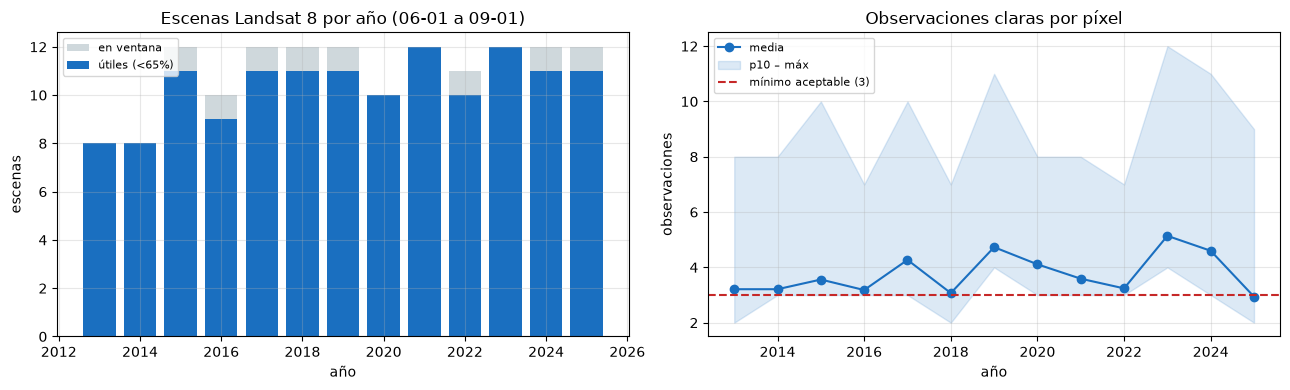

⚠ 1 año(s) por debajo de 3 observaciones claras por píxel:
 anio  escenas_utiles  obs_media calidad
 2025              11       2.94    baja

→ Revisar la celda siguiente: compara con la ventana amplia 05-15 a 09-16.

Años con datos: 13 (2013–2025)
LandTrendr exige 6 años válidos por píxel → cumplido


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

ejes[0].bar(disp["anio"], disp["escenas_total"], color="#cfd8dc", label="en ventana")
ejes[0].bar(disp["anio"], disp["escenas_utiles"], color="#1a6fc0", label=f"útiles (<{NUBES_MAX}%)")
ejes[0].set_title(f"Escenas Landsat 8 por año ({VENTANA_INI} a {VENTANA_FIN})")
ejes[0].set_ylabel("escenas")
ejes[0].legend(fontsize=8)

ejes[1].plot(disp["anio"], disp["obs_media"], "o-", color="#1a6fc0", label="media")
ejes[1].fill_between(disp["anio"], disp["obs_p10"], disp["obs_max"],
                     alpha=0.15, color="#1a6fc0", label="p10 – máx")
ejes[1].axhline(OBS_MIN_ANIO, ls="--", color="#c62828", label=f"mínimo aceptable ({OBS_MIN_ANIO})")
ejes[1].set_title("Observaciones claras por píxel")
ejes[1].set_ylabel("observaciones")
ejes[1].legend(fontsize=8)

for e in ejes:
    e.set_xlabel("año")
    e.grid(alpha=0.3)
plt.tight_layout()
plt.show()

problemas = disp[disp["calidad"] != "buena"]
if len(problemas):
    print(f"⚠ {len(problemas)} año(s) por debajo de {OBS_MIN_ANIO} observaciones claras por píxel:")
    print(problemas[["anio", "escenas_utiles", "obs_media", "calidad"]].to_string(index=False))
    print(f"\n→ Revisar la celda siguiente: compara con la ventana amplia "
          f"{VENTANA_AMPLIA[0]} a {VENTANA_AMPLIA[1]}.")
else:
    print(f"✓ Los {len(disp)} años superan el umbral de {OBS_MIN_ANIO} observaciones claras por píxel.")
    print("  La ventana jun–ago alcanza: no hace falta ampliarla.")

anios_validos = disp.loc[disp["calidad"] != "sin datos", "anio"].tolist()
print(f"\nAños con datos: {len(anios_validos)} ({anios_validos[0]}–{anios_validos[-1]})")
print(f"LandTrendr exige {OBS_MIN_SERIE} años válidos por píxel →",
      "cumplido" if len(anios_validos) >= OBS_MIN_SERIE else "NO CUMPLIDO")

### 9.1 · Comparación con la ventana amplia

Compara jun–ago (3 meses) contra 15 may – 15 sep (4 meses) para decidir con datos si vale ampliar.

El criterio **no** es "más escenas es mejor". Ampliar acerca la ventana a la estación de lluvias y
mete variación fenológica, que es el problema que la ventana estrecha evita. Así que la regla es:
ampliar **solo si** la ventana estrecha deja años por debajo del mínimo de observaciones. Si
jun–ago alcanza, se queda jun–ago aunque la amplia dé más escenas.

In [7]:
COMPARAR_VENTANAS = True   # ponlo en False si la ventana estrecha ya alcanzó y quieres ahorrar tiempo

if COMPARAR_VENTANAS:
    print(f"Comparando con la ventana amplia {VENTANA_AMPLIA[0]} a {VENTANA_AMPLIA[1]}...")
    amp = pd.DataFrame(ee.List([diagnostico(a, VENTANA_AMPLIA) for a in ANIOS]).getInfo())

    comp = pd.DataFrame({
        "anio": disp["anio"],
        "jun-ago escenas": disp["escenas_utiles"],
        "jun-ago obs/píxel": disp["obs_media"],
        "amplia escenas": amp["escenas_utiles"],
        "amplia obs/píxel": pd.to_numeric(amp["obs_media"], errors="coerce").round(2),
    })
    comp["ganancia"] = (comp["amplia obs/píxel"] - comp["jun-ago obs/píxel"]).round(2)
    display(comp.set_index("anio"))

    flojos_estrecha = int((comp["jun-ago obs/píxel"] < OBS_MIN_ANIO).sum())
    flojos_amplia = int((comp["amplia obs/píxel"] < OBS_MIN_ANIO).sum())
    print(f"\nAños por debajo de {OBS_MIN_ANIO} obs/píxel → jun-ago: {flojos_estrecha} | amplia: {flojos_amplia}")
    print(f"Ganancia media de observaciones al ampliar: +{comp['ganancia'].mean():.2f}")

    if flojos_estrecha == 0:
        print("\n→ QUEDARSE CON JUN–AGO. La ventana estrecha alcanza y es fenológicamente")
        print("  más consistente. La ganancia de observaciones no compensa el costo.")
    elif flojos_amplia < flojos_estrecha:
        print(f"\n→ AMPLIAR rescata {flojos_estrecha - flojos_amplia} año(s). Para hacerlo:")
        print("  en la celda de configuración poner  VENTANA_INI, VENTANA_FIN = VENTANA_AMPLIA")
        print("  y volver a ejecutar desde la celda de la colección anual.")
    else:
        print("\n→ QUEDARSE CON JUN–AGO: ampliar no rescata ningún año, así que no")
        print("  compensa el costo fenológico.")

Comparando con la ventana amplia 05-15 a 09-16...


,jun-ago escenas,jun-ago obs/píxel,amplia escenas,amplia obs/píxel,ganancia
anio,,,,,
2013,8,3.21,10,4.05,0.84
2014,8,3.21,12,4.78,1.57
2015,11,3.56,11,3.56,0.00
2016,9,3.18,13,4.92,1.74
2017,11,4.27,15,5.45,1.18
2018,11,3.07,15,4.66,1.59
2019,11,4.73,13,5.70,0.97
2020,10,4.11,13,5.13,1.02
2021,12,3.59,16,4.72,1.13



Años por debajo de 3 obs/píxel → jun-ago: 1 | amplia: 0
Ganancia media de observaciones al ampliar: +1.21

→ AMPLIAR rescata 1 año(s). Para hacerlo:
  en la celda de configuración poner  VENTANA_INI, VENTANA_FIN = VENTANA_AMPLIA
  y volver a ejecutar desde la celda de la colección anual.


## 10 · Visualización de control

Dos comprobaciones que buscan cosas distintas.

**Los mapas** sirven para detectar problemas espaciales: huecos de nube que la máscara no cubrió,
franjas visibles donde se solapan dos path/row (señal de que el mosaico quedó mal), o zonas enteras
sin datos. También es acá donde se verifica la decisión de enmascarar desde confianza media: si se
ve que perdimos demasiado terreno real sobre suelos claros, hay que relajar `CONF_NUBE_MIN` a 3.

**Los perfiles temporales** son la comprobación que de verdad importa, porque muestran **exactamente
lo que LandTrendr va a ver** en cada píxel. Lo que buscamos es una serie con variación suave y
quiebres identificables. Si los perfiles salen como un diente de sierra — saltando arriba y abajo
cada año — el problema está en la máscara o en la ventana, no en LandTrendr, y correr el algoritmo
sobre eso solo producirá vértices espurios. Es el momento de detectarlo, antes de invertir en la
segmentación.

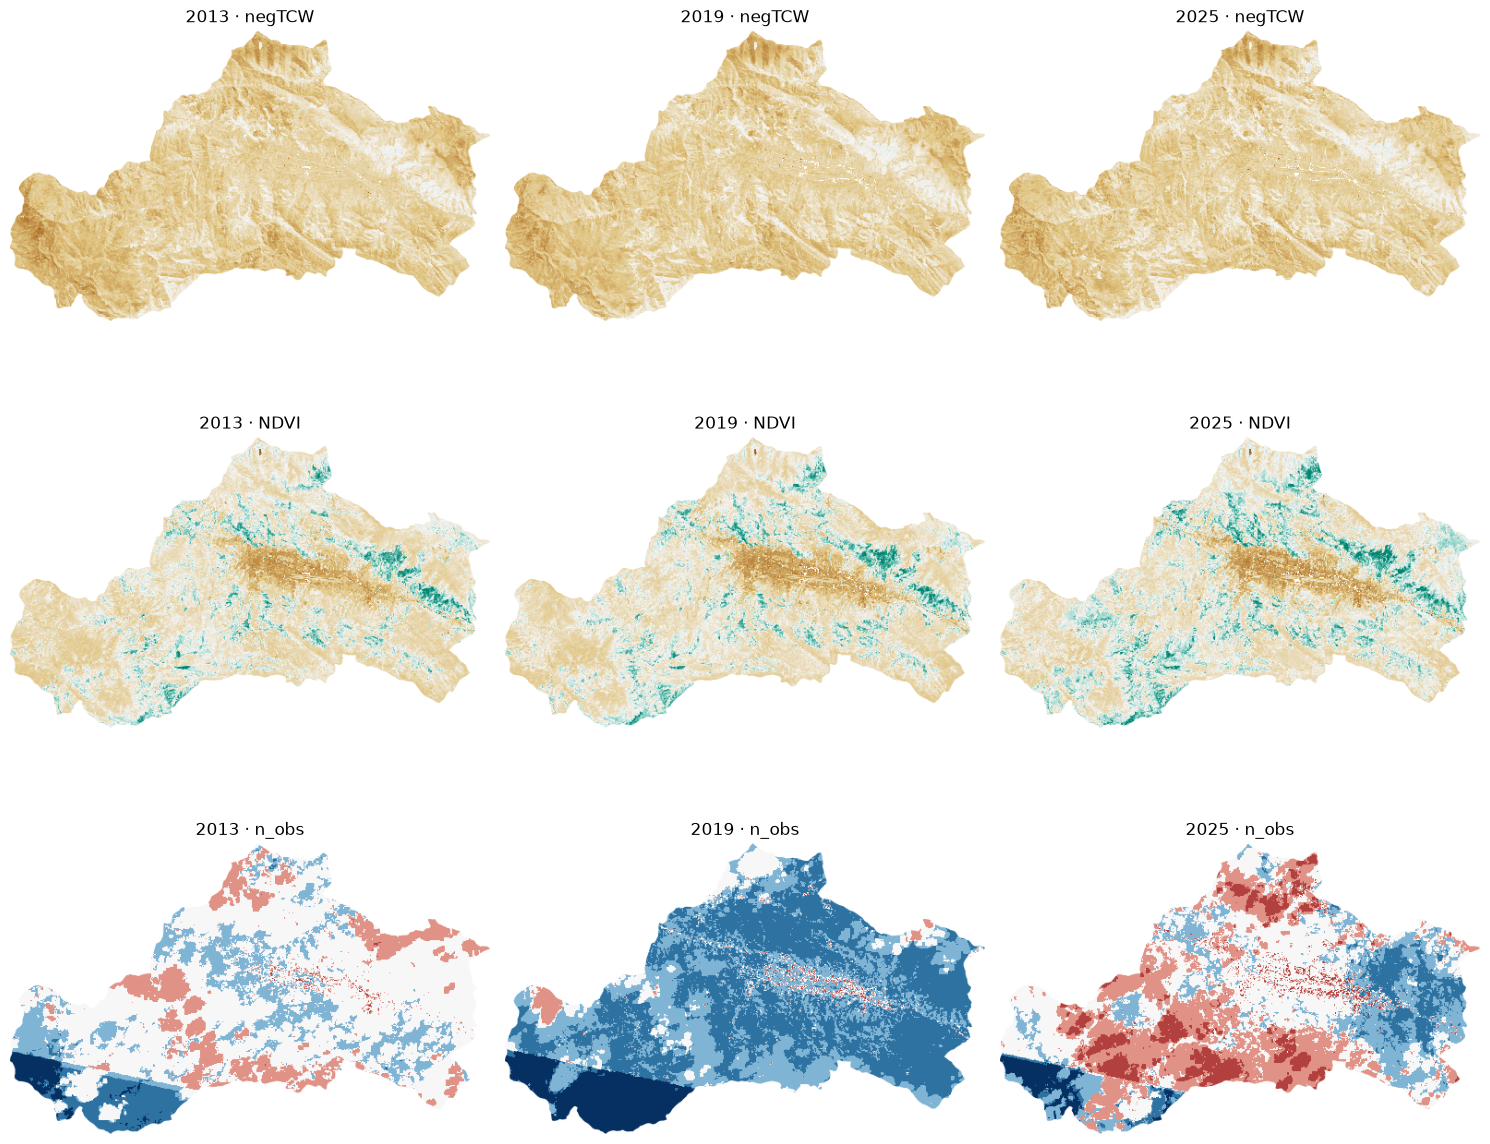

negTCW : alto (marrón) = poca humedad = candidato a degradado
NDVI   : alto (verde) = más verdor
n_obs  : rojo = pocas observaciones limpias, azul = muchas. Las zonas rojas son
         las menos confiables de la serie, hay que arrastrar este dato al análisis.


In [8]:
def miniatura(img, vis, ancho=520):
    """Miniatura PNG de una imagen recortada a la provincia."""
    from PIL import Image
    import requests, io
    url = img.getThumbURL({**vis, "region": aoi, "dimensions": ancho, "format": "png"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=180).content)))


PAL = ["#a6611a", "#dfc27d", "#f5f5f5", "#80cdc1", "#018571"]   # marrón -> verde
anios_vista = [anios_validos[0], anios_validos[len(anios_validos) // 2], anios_validos[-1]]

vis = {
    # negTCW invertido: alto = poca humedad = degradado. Paleta al revés para que el marrón sea lo seco.
    "negTCW": {"bands": ["negTCW"], "min": -0.3, "max": 0.3, "palette": PAL[::-1]},
    "NDVI": {"bands": ["NDVI"], "min": 0.0, "max": 0.8, "palette": PAL},
    "n_obs": {"bands": ["n_obs"], "min": 0, "max": 6,
              "palette": ["#67001f", "#d6604d", "#f7f7f7", "#4393c3", "#053061"]},
}

fig, ejes = plt.subplots(3, len(anios_vista), figsize=(5 * len(anios_vista), 13))
for j, anio in enumerate(anios_vista):
    img = ee.Image(serie.filter(ee.Filter.eq("year", anio)).first())
    for i, banda in enumerate(["negTCW", "NDVI", "n_obs"]):
        ejes[i][j].imshow(miniatura(img, vis[banda]))
        ejes[i][j].set_title(f"{anio} · {banda}")
        ejes[i][j].axis("off")
plt.tight_layout()
plt.show()

print("negTCW : alto (marrón) = poca humedad = candidato a degradado")
print("NDVI   : alto (verde) = más verdor")
print("n_obs  : rojo = pocas observaciones limpias, azul = muchas. Las zonas rojas son")
print("         las menos confiables de la serie, hay que arrastrar este dato al análisis.")

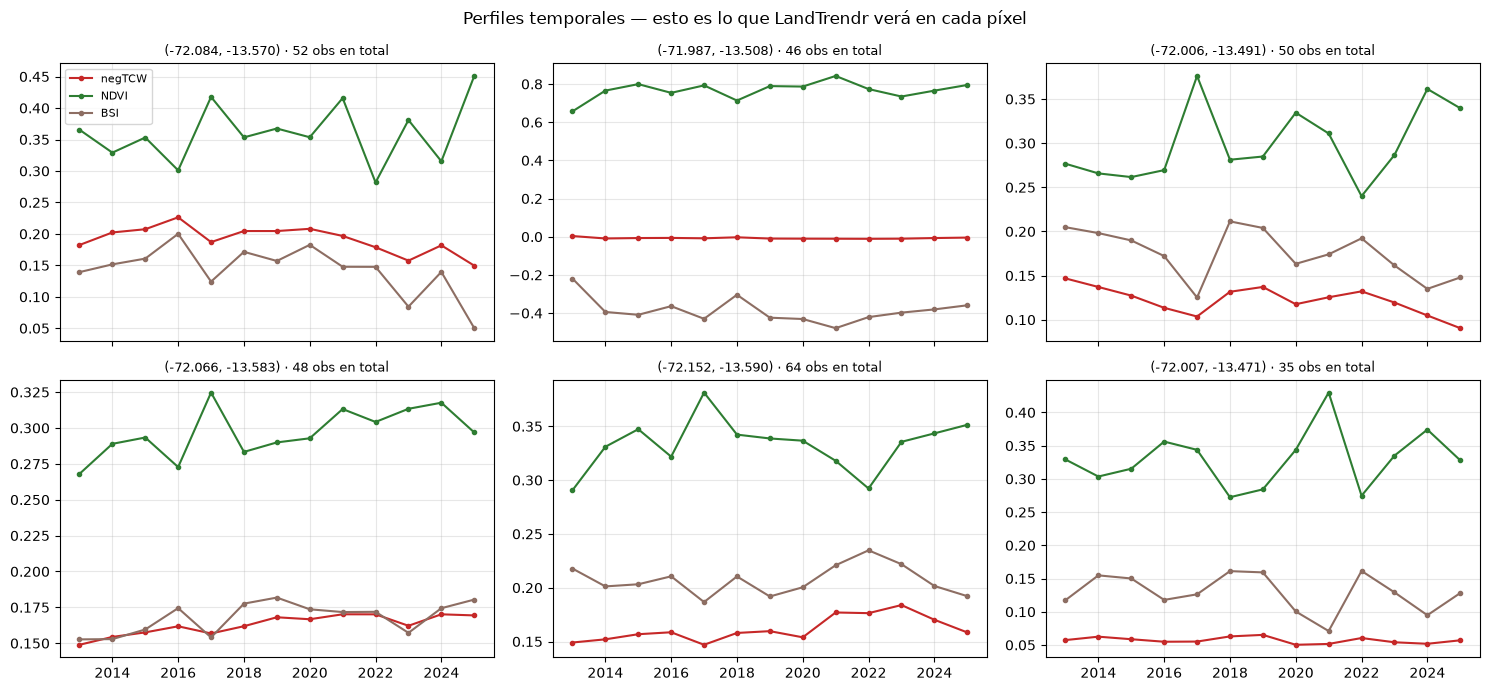

Qué buscar:
  BIEN : variación suave, con quiebres identificables si hubo cambio real
  MAL  : diente de sierra año a año → revisar máscara y ventana ANTES de correr LandTrendr
  OJO  : negTCW y NDVI deberían moverse en sentidos opuestos (negTCW está invertido)


In [9]:
# Perfiles temporales: la serie tal como la verá LandTrendr.
# Los puntos salen de un muestreo aleatorio dentro de la provincia. Para un análisis fino
# conviene reemplazarlos por coordenadas de pastizal conocidas, o por la clase de pastizal
# de MapBiomas como en el notebook 07.
N_MUESTRA = 6
puntos = ee.FeatureCollection.randomPoints(region=aoi, points=N_MUESTRA, seed=42)
coords = [f["geometry"]["coordinates"] for f in puntos.getInfo()["features"]]


def perfil(lon, lat):
    """Serie anual de todos los índices en un punto."""
    pt = ee.Geometry.Point([lon, lat])

    def extraer(img):
        v = img.reduceRegion(ee.Reducer.first(), pt, ESCALA)
        return ee.Feature(None, v.set("year", img.get("year")))

    return serie.map(extraer).getInfo()["features"]


fig, ejes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for k, (lon, lat) in enumerate(coords[:6]):
    datos = pd.DataFrame([f["properties"] for f in perfil(lon, lat)]).sort_values("year")
    eje = ejes[k // 3][k % 3]
    for banda, color in [("negTCW", "#c62828"), ("NDVI", "#2e7d32"), ("BSI", "#8d6e63")]:
        if banda in datos:
            eje.plot(datos["year"], datos[banda], "o-", ms=3, color=color, label=banda)
    n_tot = datos["n_obs"].sum() if "n_obs" in datos else 0
    eje.set_title(f"({lon:.3f}, {lat:.3f}) · {int(n_tot)} obs en total", fontsize=9)
    eje.grid(alpha=0.3)
    if k == 0:
        eje.legend(fontsize=8)

plt.suptitle("Perfiles temporales — esto es lo que LandTrendr verá en cada píxel")
plt.tight_layout()
plt.show()

print("Qué buscar:")
print("  BIEN : variación suave, con quiebres identificables si hubo cambio real")
print("  MAL  : diente de sierra año a año → revisar máscara y ventana ANTES de correr LandTrendr")
print("  OJO  : negTCW y NDVI deberían moverse en sentidos opuestos (negTCW está invertido)")

## 11 · Exportación

Un GeoTIFF por año con los 7 índices y la banda `n_obs`, en `EPSG:32719` a 30 m, recortado a la
provincia.

**Sobre la grilla.** La exportación se ancla a los píxeles nativos de Landsat (misma lógica que el
notebook 06) en vez de a una grilla redonda arbitraria. Si Landsat ya está en la zona UTM de salida,
los píxeles coinciden uno a uno y **no hay remuestreo**. Esto importa: cualquier remuestreo mezcla
valores de píxeles vecinos, y en una serie temporal donde comparamos el mismo píxel entre años, un
desplazamiento de medio píxel introduce una diferencia que no está en el terreno.

**Los metadatos se escriben en el GeoTIFF** (ventana, número de escenas, regla de nubes,
configuración de la máscara, factores de escala, coeficientes de Tasseled Cap). Un archivo que no
dice cómo se hizo es inservible en seis meses.

**La exportación está apagada** (`EXPORTAR = False`). Son 13 archivos y tarda. Para correrla, poner
`EXPORTAR = True` y re-ejecutar la celda. Si la descarga directa falla, cae automáticamente a una
tarea de Google Drive, igual que en el notebook 06.

In [10]:
DESC_BANDAS = INDICES + ["n_obs"]

# Grilla de salida anclada a los píxeles nativos de Landsat, para no remuestrear
esc_ref = ee.Image(escenas_anio(anios_validos[-1]).first())
nativa = esc_ref.select("SR_B2").projection().getInfo()
print("Grilla nativa de Landsat:", nativa["crs"], nativa["transform"])

if nativa["crs"] == GRID_CRS:
    off_x, off_y = nativa["transform"][2] % ESCALA, nativa["transform"][5] % ESCALA
    print(f"→ Landsat ya está en {GRID_CRS}: la grilla se alinea con sus píxeles, sin remuestreo.")
else:
    off_x, off_y = 0.0, 0.0
    print(f"⚠ Landsat está en {nativa['crs']}, no en {GRID_CRS}: al reproyectar, GEE remuestrea")
    print(f"  con vecino más cercano. Es lo menos malo (no inventa valores nuevos), pero")
    print(f"  conviene tenerlo documentado.")

xmin, ymin, xmax, ymax = prov.to_crs(epsg=32719).total_bounds
x0 = math.floor((xmin - off_x) / ESCALA) * ESCALA + off_x
y0 = math.ceil((ymax - off_y) / ESCALA) * ESCALA + off_y
GRID_TRANSFORM = [ESCALA, 0, x0, 0, -ESCALA, y0]
NCOLS = math.ceil((xmax - x0) / ESCALA)
NFILAS = math.ceil((y0 - ymin) / ESCALA)

mb_anio = NCOLS * NFILAS * len(DESC_BANDAS) * 4 / 1e6
print(f"\nGrilla de salida: {GRID_CRS}  {GRID_TRANSFORM}")
print(f"Tamaño: {NCOLS} × {NFILAS} píxeles | {len(DESC_BANDAS)} bandas float32")
print(f"Peso por año: ~{mb_anio:.0f} MB sin comprimir")
print(f"Total ({len(anios_validos)} años): ~{mb_anio * len(anios_validos) / 1000:.2f} GB sin comprimir")
print("Destino:", SALIDA)

Grilla nativa de Landsat: EPSG:32718 [30, 0, 707985, 0, -30, 8676415]
⚠ Landsat está en EPSG:32718, no en EPSG:32719: al reproyectar, GEE remuestrea
  con vecino más cercano. Es lo menos malo (no inventa valores nuevos), pero
  conviene tenerlo documentado.

Grilla de salida: EPSG:32719  [30, 0, 157110.0, 0, -30, 8513430.0]
Tamaño: 1310 × 817 píxeles | 8 bandas float32
Peso por año: ~34 MB sin comprimir
Total (13 años): ~0.45 GB sin comprimir
Destino: F:\Cobertura de suelo\outputs\04_serie_anual_landsat


In [ ]:
EXPORTAR = True     # ponlo en True para descargar


def tags_compuesto(anio, n_escenas):
    """Metadatos del compuesto, para que el GeoTIFF se explique solo."""
    return {
        "YEAR": str(anio),
        "WINDOW": f"{anio}-{VENTANA_INI} to {anio}-{VENTANA_FIN} (fin exclusivo)",
        "COMPOSITE": "medoid",
        "N_SCENES": str(n_escenas),
        "SATELLITE": "LANDSAT_8",
        "COLLECTION": COLECCION,
        "CLOUD_RULE": f"CLOUD_COVER_LAND<{NUBES_MAX}",
        "QA_MASK": (f"QA_PIXEL bits 0-{'5' if ENMASCARAR_NIEVE else '4'}, "
                    f"cloud_conf>={CONF_NUBE_MIN}, shadow_conf=high, cirrus_conf=high, "
                    f"QA_RADSAT!=0, aerosol_high={ENMASCARAR_AEROSOL}"),
        "SCALE_FACTOR": "0.0000275",
        "SCALE_OFFSET": "-0.2",
        "TC_COEFFICIENTS": TC_FUENTE,
        "PRIMARY_INDEX": INDICE_PRIMARIO,
        "FTV_INDICES": ",".join(INDICES_FTV),
        "BANDS": ",".join(DESC_BANDAS),
    }


def escribir_metadatos(ruta, tags, descripciones):
    """Escribe tags y descripciones de banda en un GeoTIFF local."""
    try:
        import rasterio
    except ImportError:
        print("  falta rasterio (pip install rasterio): no se escriben los metadatos")
        return False
    with rasterio.open(ruta, "r+") as dst:
        dst.update_tags(**tags)
        if len(descripciones) == dst.count:
            dst.descriptions = tuple(descripciones)
    return True


def descargar(img, ruta, dtype="float32"):
    """Descarga un GeoTIFF con geemap. Si falla, lanza una tarea de exportación a Drive."""
    try:
        geemap.download_ee_image(img, str(ruta), region=aoi, crs=GRID_CRS,
                                 crs_transform=GRID_TRANSFORM, dtype=dtype, overwrite=True)
        return "descarga directa (geemap)"
    except Exception as e:
        print("  descarga directa falló:", repr(e)[:200])
        tarea = ee.batch.Export.image.toDrive(
            image=img, description=ruta.stem[:100], folder="cobertura_cusco",
            fileNamePrefix=ruta.stem, region=aoi, crs=GRID_CRS,
            crsTransform=GRID_TRANSFORM, maxPixels=1e10)
        tarea.start()
        return "tarea a Google Drive (carpeta cobertura_cusco)"


manifiesto = []
if EXPORTAR:
    SALIDA.mkdir(parents=True, exist_ok=True)
    for anio in anios_validos:
        ruta = SALIDA / f"indices_anual_{anio}.tif"
        img = ee.Image(serie.filter(ee.Filter.eq("year", anio)).first())
        n_esc = int(escenas_anio(anio).size().getInfo())
        print(f"{anio}: {ruta.name} ({n_esc} escenas)...")
        via = descargar(img.select(DESC_BANDAS).toFloat(), ruta)
        if ruta.exists():
            escribir_metadatos(ruta, tags_compuesto(anio, n_esc), DESC_BANDAS)
        manifiesto.append({"anio": anio, "archivo": ruta.name, "escenas": n_esc, "via": via,
                           "MB": round(ruta.stat().st_size / 1e6, 1) if ruta.exists() else None})
        print("  ", via)

    man = pd.DataFrame(manifiesto)
    man.to_csv(SALIDA / "manifiesto.csv", index=False)
    display(man)
    print("Manifiesto guardado en", SALIDA / "manifiesto.csv")
else:
    print("EXPORTAR = False.")
    print(f"Pon EXPORTAR = True y re-ejecuta esta celda para generar {len(anios_validos)} archivos en:")
    print(" ", SALIDA)

# La tabla de disponibilidad se guarda igual, exportes o no: es el registro de calidad de la serie
SALIDA.mkdir(parents=True, exist_ok=True)
disp.to_csv(SALIDA / "disponibilidad_anual.csv", index=False)
print("\nTabla de disponibilidad guardada en", SALIDA / "disponibilidad_anual.csv")

EXPORTAR = False.
Pon EXPORTAR = True y re-ejecuta esta celda para generar 13 archivos en:
  F:\Cobertura de suelo\outputs\04_serie_anual_landsat

Tabla de disponibilidad guardada en F:\Cobertura de suelo\outputs\04_serie_anual_landsat\disponibilidad_anual.csv


## 9 · Exportar la serie anual como asset

Esta celda estaba en el notebook de LandTrendr y se movió aquí, que es donde corresponde: el
notebook que **produce** la serie es el que debe exportarla.

### Por qué el asset no es opcional

Earth Engine es perezoso y **no guarda resultados intermedios**. La colección `serie` que construye
este notebook no son 13 imágenes calculadas: es una *receta* que describe cómo calcularlas. Cada vez
que alguien pide un número, un mapa o una descarga, la receta se ejecuta entera desde las escenas
crudas — filtrar, enmascarar, calcular distancias multibanda, elegir el medoide, siete índices, por
trece años.

Mientras eso ocurra dentro de LandTrendr, que a su vez segmenta y manipula arrays, el cómputo por
tesela desborda la memoria y aparece `Computed image is too large`. No es un problema de tamaño del
área: son 530 km². Es profundidad de la cadena.

Exportar al asset convierte la receta en **imágenes de verdad**, almacenadas en el servidor. A
partir de ahí leer un píxel es leer un píxel.

Como efecto secundario, congela los insumos: si mañana se reprocesa la colección de Landsat, los
resultados no se mueven solos.

### Qué produce

Una colección de assets con una imagen por año, de 8 bandas cada una (los 7 índices más `n_obs`).
Son 13 tareas de exportación; con 530 km² tardan pocos minutos. Se siguen desde la pestaña **Tasks**
del Code Editor o con `ee.batch.Task.list()`.

In [ ]:
ASSET_SERIE = f"projects/{GEE_PROJECT}/assets/cusco_04_serie_anual"
EXPORTAR_ASSET = True          # ponlo en True una sola vez

if EXPORTAR_ASSET:
    # La colección tiene que existir antes de escribir imágenes dentro
    try:
        ee.data.createAsset({"type": "ImageCollection"}, ASSET_SERIE)
        print("Colección creada:", ASSET_SERIE)
    except Exception as e:
        print("La colección ya existía o no se pudo crear:", repr(e)[:120])

    tareas = []
    for anio in anios_validos:
        img = (ee.Image(serie.filter(ee.Filter.eq("year", anio)).first())
               .select(INDICES + ["n_obs"]).toFloat())
        t = ee.batch.Export.image.toAsset(
            image=img,
            description=f"cusco_serie_{anio}",
            assetId=f"{ASSET_SERIE}/indices_{anio}",
            region=aoi, scale=ESCALA, crs=GRID_CRS, maxPixels=1e10,
            pyramidingPolicy={".default": "mean"})
        t.start()
        tareas.append((anio, t.id))
        print(f"  {anio} → tarea {t.id}")

    print(f"\n{len(tareas)} tareas lanzadas hacia {ASSET_SERIE}")
    print("Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()")
    print("Cuando terminen, el notebook 05 las lee con ee.ImageCollection(ASSET_SERIE).")
else:
    print("EXPORTAR_ASSET = False.")
    print(f"Ponlo en True y ejecuta esta celda UNA VEZ: genera {len(anios_validos)} imágenes en")
    print(" ", ASSET_SERIE)
    print("\nSin este asset, el notebook 05 recalcula el medoide de 13 años en cada")
    print("evaluación y choca con 'Computed image is too large'.")

EXPORTAR_ASSET = False.
Ponlo en True y ejecuta esta celda UNA VEZ: genera 13 imágenes en
  projects/viirs-peru/assets/cusco_04_serie_anual

Sin este asset, el notebook 05 recalcula el medoide de 13 años en cada
evaluación y choca con 'Computed image is too large'.


## 12 · Resumen y qué sigue

Deja por escrito el estado de la serie: qué años son confiables, qué quedó guardado y qué entra
como insumo al notebook de LandTrendr.

In [13]:
buenos = disp[disp["calidad"] == "buena"]["anio"].tolist()
bajos = disp[disp["calidad"] == "baja"]["anio"].tolist()
sin_datos = disp[disp["calidad"] == "sin datos"]["anio"].tolist()

print("=" * 76)
print("RESUMEN · notebook 08 · compuestos anuales de Landsat 8")
print("=" * 76)
print(f"Área      : provincia de Cusco, {area_km2:,.0f} km² (límite INEI)")
print(f"Periodo   : {ANIOS[0]}–{ANIOS[-1]}  ({len(ANIOS)} años)")
print(f"Satélite  : Landsat 8 únicamente ({COLECCION})")
print(f"Ventana   : {VENTANA_INI} a {VENTANA_FIN} — estación seca plena")
print(f"Compuesto : medoide | Tasseled Cap: {TC_FUENTE}")
print()
print(f"Años buenos (>={OBS_MIN_ANIO} obs/píxel) : {len(buenos):2d}  {buenos}")
print(f"Años de baja calidad (1–2 obs)      : {len(bajos):2d}  {bajos or '—'}")
print(f"Años sin datos                      : {len(sin_datos):2d}  {sin_datos or '—'}")
print(f"Media de observaciones por píxel/año : {disp['obs_media'].mean():.2f}")
print()
print(f"Índice primario (segmentación) : {INDICE_PRIMARIO}")
print(f"Acompañantes (ftvList)         : {', '.join(INDICES_FTV)}")
print(f"Control de calidad por píxel   : banda n_obs")
print()
if len(buenos) >= OBS_MIN_SERIE:
    print(f"✓ {len(buenos)} años buenos, por encima de los {OBS_MIN_SERIE} que exige LandTrendr.")
else:
    print(f"⚠ Solo {len(buenos)} años buenos, por debajo de los {OBS_MIN_SERIE} de minObservationsNeeded.")
    print("  Considerar la ventana amplia antes de seguir.")
print()
print("-" * 76)
print("SIGUIENTE · notebook 09 · LandTrendr")
print("-" * 76)
print(f"1. Segmentar con {INDICE_PRIMARIO} y pasar {', '.join(INDICES_FTV)}")
print("   como ftvList en la MISMA corrida. Una sola ejecución, no una por índice:")
print("   los vértices los define solo el índice primario y los demás se ajustan en ellos.")
print()
print("2. Parámetros iniciales (a calibrar, no definitivos):")
print("     maxSegments=4          · el default 6 sobresegmenta con solo 13 años")
print("     spikeThreshold=0.9")
print("     vertexCountOvershoot=3")
print("     preventOneYearRecovery=True  · en pastizal los rebotes de 1 año son lluvia, no recuperación")
print("     recoveryThreshold=0.25 · probar también 0.5")
print("     pvalThreshold=0.05")
print("     bestModelProportion=0.75")
print("     minObservationsNeeded=6")
print("   Calibrar con una grilla contra puntos interpretados, eligiendo por F1 de")
print("   detección de vértices y concordancia del año (±1). NO por RMSE.")
print()
print("3. Enmascarar antes de interpretar: píxeles con n_obs < 3 en demasiados años,")
print("   píxeles fuera de la clase pastizal, y bordes entre coberturas.")
print()
print("4. Validación: muestreo estratificado (Olofsson et al. 2014) con interpretación")
print("   tipo TimeSync y estimación de área con IC 95%. NO holdout temporal:")
print("   LandTrendr es segmentación no supervisada, no se entrena ni predice.")
print()
print("5. Pendiente: capa de atribución climática (RESTREND con CHIRPS o PISCO) para")
print("   separar degradación antrópica de respuesta a sequía. En pastizal semiárido")
print("   el verdor de época seca depende de la lluvia de la estación húmeda previa.")
print("=" * 76)

RESUMEN · notebook 08 · compuestos anuales de Landsat 8
Área      : provincia de Cusco, 530 km² (límite INEI)
Periodo   : 2013–2025  (13 años)
Satélite  : Landsat 8 únicamente (LANDSAT/LC08/C02/T1_L2)
Ventana   : 06-01 a 09-01 — estación seca plena
Compuesto : medoide | Tasseled Cap: Baig2014

Años buenos (>=3 obs/píxel) : 12  [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Años de baja calidad (1–2 obs)      :  1  [2025]
Años sin datos                      :  0  —
Media de observaciones por píxel/año : 3.76

Índice primario (segmentación) : negTCW
Acompañantes (ftvList)         : NDVI, MSAVI, TCG, TCB, BSI, NDMI
Control de calidad por píxel   : banda n_obs

✓ 12 años buenos, por encima de los 6 que exige LandTrendr.

----------------------------------------------------------------------------
SIGUIENTE · notebook 09 · LandTrendr
----------------------------------------------------------------------------
1. Segmentar con negTCW y pasar NDVI, MSAVI, TCG, TCB, B